In [51]:
import importlib
import rww_pytorch_model
importlib.reload(rww_pytorch_model)


from rww_pytorch_model import ParamsJR
from rww_pytorch_model import RNNWWD
from rww_pytorch_model import Model_fitting
import matplotlib.pyplot as plt # for plotting
import numpy as np # for numerical operations
import pandas as pd # for data manipulation
import seaborn as sns # for plotting 
import time # for timer
from nilearn import image
import pickle
import itertools
import os

In [41]:
def file_paths(stim_site, sub_id, parcellation, session, gsr = None):

    sub_id = str(sub_id)
    session = str(session)

    if 'B' in sub_id or 'S' in sub_id:
        stim_type = 'Sham'
    else:
        stim_type = 'Active'


    ses_path = '../data/' + stim_site + '/' + stim_type + '/' + sub_id + '/ses-0' + session
    sc_path =  ses_path + '/dMRI/cm_nodes_' + parcellation + '.nii.gz_count.csv'
    atlas_path = ses_path + '/atlases/' + sub_id + '_' + parcellation + '.nii.gz'

    if stim_site == 'DLPFC' or stim_site == 'RIFG':
        bold_path = ses_path + '/REST/sub-' + sub_id[1:] + '_ses-0' + session + '_' + (gsr * "no") + 'GSR_Filtered_4DVolume.nii'   
    elif stim_site == 'PSTS':
        bold_path = ses_path + '/REST/' + sub_id[1:] + '_0' + session + '_R_MEICA_T1c_medn_nlw.nii.gz'

    return sc_path, bold_path, atlas_path


def model_fit(stim_site, session, sub_id, parcellation, max_parcels, num_epochs = 20, save = False, csv_path = None, gsr = None):

    start_time = time.time()

    
    sc_path, bold_path, atlas_path = file_paths(stim_site = stim_site, sub_id = sub_id, parcellation = parcellation, 
                                                session = session, gsr = gsr)

    #structural
    #sc_file = '../dlPFC/sub-4602/anat/DWI/cm_nodes_Schaefer100+Tian+Suit.nii.gz_count.csv'
    sc = np.loadtxt(sc_path, delimiter = ',')[0:max_parcels, 0:max_parcels]#[0:100, 0:100]

    #print(np.shape(sc), np.max(sc), np.min(sc))

    sc = sc -np.diag(np.diag(sc))
    sc = 0.5*(sc.T+sc)
    sc = np.log1p(sc)/np.linalg.norm(np.log1p(sc))
    print(np.shape(sc))

    dist = np.nan_to_num(1/sc)
    dist[dist> 200] = 0

    #functional
    #bold = image.load_img('../dlPFC/sub-4602/func/sub-4602_ses-01_task-rest_space-MNI152NLin6Asym_res-02_desc-denoisedSmoothed_bold.nii.gz')
    bold = image.load_img(bold_path)
    bold_data = image.get_data(bold)

    atlas = image.load_img(atlas_path)
    atlas = image.resample_to_img(atlas, image.index_img(bold, 1), interpolation = 'nearest')
    atlas_data = image.get_data(atlas)
    atlas_data[atlas_data > max_parcels] = 0 #only looking at schaefer 100
    n_parcels = int(np.max(atlas_data))
    n_time = int(np.shape(bold_data)[3])

    ts = np.zeros(((n_time, n_parcels)))
    for i_parcel in range(n_parcels):
        for i_time in range(n_time):
            ts[i_time, i_parcel] = np.mean(bold_data[:,:,:,i_time][atlas_data == i_parcel + 1])
    ts = ts/np.max(ts)
    #ts = (ts - np.mean(ts))/np.std(ts) #trying z scores to account for differences in baseline scanner intensity
    
    
    fc_emp = np.corrcoef(ts.T)

    #print(fc_emp)


    node_size = n_parcels
    output_size = n_parcels
    #num_epochs = 200
    batch_size =20
    step_size = .05
    input_size = 2
    tr = 2.5 #changed

    ## call WWD module
    par = ParamsJR("WWD", g = [80,.2], g_EE= [0.5, 5], g_IE= [0.5, 5], \
                        g_EI= [0.16963709468378746, 10], I_0=[0.39410256410256406, 10],\
                        std_in=[0.02, 0],  mu = [2.5, 5])



    """par = ParamsJR("WWD", g = [20, 0], g_EE= [3.393939393939394, 0], g_IE= [10.260801579764808, 0], \
                        g_EI= [0.3290554714188569, 0], I_0= [0.39410256410256406, 0], tau_E =[0.05, 0], tau_I =[ 0.01, 0], gamma_E= [0.641, 0], gamma_I = [1, 0],\
                        std_in=[0.05, 0],  mu = [5.5, 0])# Get the WWD model module for forward in a batch.""" 
    """par = ParamsJR("WWD", g = [2, 0], g_EE= [3.5, 0], g_IE= [2.5, 0], \
                        g_EI= [3.75, 0], I_0= [0.382, 0], tau_E =[ 0.01, 0], tau_I =[ 0.02, 0], gamma_E= [0.641, 0], gamma_I = [1, 0],\
                        std_in=[0.01, 0],  mu = [5.5, 0])# Get the WWD model module for forward in a batch."""
    model = RNNWWD(input_size, node_size, batch_size, step_size, tr, sc, dist, True,  par)





    data_mean = [ts.T]*num_epochs
    data_mean =np.array(data_mean)
    # call model fit method
    #lr is 0.001 by default
    F = Model_fitting(model, data_mean, num_epochs, 1, 0.001)

    # fit data(train)

    output_train = F.train()

    X0 = 0.45 * np.random.uniform(0, 1, (node_size, 6)) + np.array(
                [0, 0, 0, 1.0, 1.0, 1.0])
    hE0 = np.random.uniform(0, 5, (node_size, 500))
    base_batch_num = 20
    output_test = F.test(X0, hE0, base_batch_num)
    #output_test = F.test(120)
    fc_test = np.corrcoef(F.output_sim.bold_test)

    fig, ax = plt.subplots(1,3, figsize=(12,8))
    ax[1].imshow(fc_emp-np.diag(np.diag(fc_emp)), cmap='bwr')
    ax[1].set_title('Empirical FC')
    ax[0].plot(F.output_sim.bold_test.T)
    ax[0].set_title('Test')
    ax[2].imshow(fc_test-np.diag(np.diag(fc_test)), cmap='bwr')
    ax[2].set_title('Test FC')
    

    if save:

        df = pd.read_csv(csv_path, header = 0, index_col = 0)
        desc = sub_id + '_ses-0' + str(session) + '_' + parcellation + '_parcels' +  str(max_parcels) + '_epoch' + str(num_epochs)
        if stim_site == 'DLPFC' or stim_site == 'RIFG':
            desc += '_' + (not gsr * 'no') + 'GSR'

        sub_dir = 'rww_res/' + stim_site + '/' + sub_id
        if not os.path.isdir(sub_dir):
            os.mkdir(sub_dir)

        plt.savefig(sub_dir + '/' + desc + '.png')
        np.savetxt(sub_dir + '/' + desc + '_fc_emp.csv', fc_emp)
        np.savetxt(sub_dir + '/' + desc + '_fc_test.csv', fc_test)
        r = np.corrcoef(fc_emp.flatten(), fc_test.flatten())[0,1]
        df.loc[desc] = [sub_id, session, stim_site, parcellation, max_parcels, num_epochs, gsr, r]
        df.to_csv(csv_path)

    plt.show()

    end_time =  time.time()
    print('running time is  {0} \'s'.format(end_time - start_time ))

def iterate(stim_sites, sessions, parcellations, epochs, csv_path, use_gsr = [True, False], check_csv = True):
    for stim_site, session, parcellation, num_epochs in itertools.product(stim_sites, sessions, parcellations, epochs):
        for sub_id, max_parcels in itertools.product(stim_sites[stim_site], parcellations[parcellation], use_gsr):
            
            df = pd.read_csv(csv_path, header = 0, index_col = 0)
            desc = sub_id + '_ses-0' + str(session) + '_' + parcellation + '_parcels' +  str(max_parcels) + '_epoch' + str(num_epochs)
            if stim_site == 'DLPFC' or stim_site == 'RIFG':
                desc += '_' + (not gsr * 'no') + 'GSR'
            elif stim_site == 'PSTS':
                gsr = None

            if 'B' in sub_id or 'S' in sub_id:
                stim_type = 'Sham'
            else:
                stim_type = 'Active'

            
            run_participant = True
            if check_csv:
                run_participant = not desc in df.index

            if run_participant:
                print(sub_id, stim_site, stim_type, session, parcellation, max_parcels, num_epochs)
                try:
                    model_fit(stim_site = stim_site, stim_type = stim_site, session = session, sub_id = sub_id, parcellation = parcellation,
                          max_parcels = max_parcels, num_epochs = num_epochs, save = True,  csv_path = csv_path)
                except:
                    print(sub_id + '_error')


In [52]:
model_fit(stim_site = 'DLPFC', session = 1, sub_id = 'A4602', parcellation = 'Schaefer100+Tian+Suit', max_parcels = 184, num_epochs = 1, save = False, csv_path = None, gsr = True)


(184, 184)


/tmp/ipykernel_3514955/4186804181.py:43: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


epoch:  0 522.5266


ValueError: Incompatible dimension for X and Y matrices: X.shape[1] == 160 while Y.shape[1] == 176

In [54]:
np.shape(pd.read_pickle('../temp/tmp_ls.pkl'))

(8, 184, 20)

In [ ]:

stim_site = 'dlPFC'
session = 1
sub_id = '4615'
parcellation = 'Schaefer200+Tian+Suit'
max_parcels = 284
csv_path = 'placeholder'
num_epochs = 1
save = False
stim_type = None

sc_path, bold_path, atlas_path = file_paths(stim_site = stim_site, sub_id = sub_id, parcellation = parcellation,
                                            stim_type = stim_type, session = session)

#structural
#sc_file = '../dlPFC/sub-4602/anat/DWI/cm_nodes_Schaefer100+Tian+Suit.nii.gz_count.csv'
sc = np.loadtxt(sc_path, delimiter = ',')[0:max_parcels, 0:max_parcels]#[0:100, 0:100]

#print(np.shape(sc), np.max(sc), np.min(sc))

sc = sc -np.diag(np.diag(sc))
sc = 0.5*(sc.T+sc)
sc = np.log1p(sc)/np.linalg.norm(np.log1p(sc))
print(np.shape(sc))

dist = np.nan_to_num(1/sc)
dist[dist> 200] = 0

#functional
#bold = image.load_img('../dlPFC/sub-4602/func/sub-4602_ses-01_task-rest_space-MNI152NLin6Asym_res-02_desc-denoisedSmoothed_bold.nii.gz')
bold = image.load_img(bold_path)
bold_data = image.get_data(bold)

atlas = image.load_img(atlas_path)
atlas = image.resample_to_img(atlas, image.index_img(bold, 1), interpolation = 'nearest')
atlas_data = image.get_data(atlas)
atlas_data[atlas_data > max_parcels] = 0 #only looking at schaefer 100
n_parcels = int(np.max(atlas_data))
n_time = int(np.shape(bold_data)[3])

ts = np.zeros(((n_time, n_parcels)))
for i_parcel in range(n_parcels):
    for i_time in range(n_time):
        ts[i_time, i_parcel] = np.mean(bold_data[:,:,:,i_time][atlas_data == i_parcel + 1])
ts = ts/np.max(ts)
#ts = (ts - np.mean(ts))/np.std(ts) #trying z scores to account for differences in baseline scanner intensity


fc_emp = np.corrcoef(ts.T)

#print(fc_emp)


node_size = n_parcels
output_size = n_parcels
#num_epochs = 200
#batch_size =20 #trying batch size of 16 to see if it cleanly divides in 176
batch_size = 16
step_size = .05
input_size = 2
tr = 2.5 #changed

## call WWD module
par = ParamsJR("WWD", g = [80,.2], g_EE= [0.5, 5], g_IE= [0.5, 5], \
                    g_EI= [0.16963709468378746, 10], I_0=[0.39410256410256406, 10],\
                    std_in=[0.02, 0],  mu = [2.5, 5])



"""par = ParamsJR("WWD", g = [20, 0], g_EE= [3.393939393939394, 0], g_IE= [10.260801579764808, 0], \
                    g_EI= [0.3290554714188569, 0], I_0= [0.39410256410256406, 0], tau_E =[0.05, 0], tau_I =[ 0.01, 0], gamma_E= [0.641, 0], gamma_I = [1, 0],\
                    std_in=[0.05, 0],  mu = [5.5, 0])# Get the WWD model module for forward in a batch.""" 
"""par = ParamsJR("WWD", g = [2, 0], g_EE= [3.5, 0], g_IE= [2.5, 0], \
                    g_EI= [3.75, 0], I_0= [0.382, 0], tau_E =[ 0.01, 0], tau_I =[ 0.02, 0], gamma_E= [0.641, 0], gamma_I = [1, 0],\
                    std_in=[0.01, 0],  mu = [5.5, 0])# Get the WWD model module for forward in a batch."""
model = RNNWWD(input_size, node_size, batch_size, step_size, tr, sc, dist, True,  par)





data_mean = [ts.T]*num_epochs
data_mean =np.array(data_mean)
# call model fit method
#lr is 0.001 by default
F = Model_fitting(model, data_mean, num_epochs, 1, 0.001)

(284, 284)


/tmp/ipykernel_652088/1537008855.py:25: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


KeyboardInterrupt: 

In [16]:
F.output_sim.E_train

[]

In [32]:
F.model

RNNWWD()

In [75]:
import torch

In [85]:
X = torch.tensor(0.45 * np.random.uniform(0, 1, (F.model.node_size, F.model.state_size)) + np.array(
                [0, 0, 0, 1.0, 1.0, 1.0]), dtype=torch.float32)

hE = torch.tensor(np.random.uniform(state_lb, state_ub, (F.model.node_size, delays_max)),
                  dtype=torch.float32)

In [90]:
i_batch = 2
base_batch_num = 20
external = torch.tensor(np.zeros([F.model.node_size, F.model.hidden_size, F.model.batch_size]),
                                    dtype=torch.float32)
noise_in = torch.tensor(np.random.randn(F.model.node_size, F.model.hidden_size, 
                                        F.model.batch_size, F.model.input_size), dtype=torch.float32)

noise_out = torch.tensor(np.random.randn(F.model.node_size, F.model.batch_size), dtype=torch.float32)




state_lb = 0
state_ub = 5
delays_max = 500

next_batch2, hE_new2 = F.model(external, noise_in, noise_out, X, hE)

X = torch.tensor(next_batch2['current_state'].detach().numpy(), dtype=torch.float32)
hE = torch.tensor(hE_new2.detach().numpy(), dtype=torch.float32)

In [87]:
next_batch

{'current_state': tensor([[ 0.2098,  0.0968,  0.0034,  1.0877,  1.0270,  0.9598],
         [ 0.2088,  0.1247,  0.0044,  1.0906,  1.0278,  0.9599],
         [ 0.2184,  0.1191,  0.0047,  1.0890,  1.0273,  0.9595],
         ...,
         [ 0.1609,  0.1084, -0.0094,  1.0842,  1.0268,  0.9599],
         [ 0.2183,  0.0436, -0.0019,  1.0873,  1.0274,  0.9592],
         [ 0.1672,  0.1475, -0.0085,  1.0631,  1.0210,  0.9657]],
        grad_fn=<CatBackward0>),
 'bold_batch': tensor([[1.9380, 1.3259, 1.3189,  ..., 1.3471, 1.3286, 1.3061],
         [1.8875, 1.2117, 1.3037,  ..., 1.2707, 1.2436, 1.2422],
         [1.8186, 1.2042, 1.2665,  ..., 1.2574, 1.2630, 1.3091],
         ...,
         [2.0600, 1.1422, 1.0920,  ..., 1.2195, 1.1775, 1.2655],
         [2.1085, 1.0885, 1.1240,  ..., 1.1571, 1.1620, 1.2665],
         [2.4170, 0.9637, 1.0799,  ..., 1.1720, 1.1546, 1.0654]],
        grad_fn=<CatBackward0>),
 'E_batch': tensor([[0.3149, 0.3143, 0.3049,  ..., 0.2224, 0.2321, 0.2098],
         [0.1447,

In [89]:
next_batch1

{'current_state': tensor([[ 2.1369e-01,  1.0797e-01,  3.3755e-05,  1.0904e+00,  1.0280e+00,
           9.5844e-01],
         [ 2.0747e-01,  1.1715e-01, -3.3796e-03,  1.0915e+00,  1.0285e+00,
           9.5880e-01],
         [ 1.9798e-01,  1.1379e-01, -1.9538e-03,  1.0864e+00,  1.0269e+00,
           9.5947e-01],
         ...,
         [ 2.2117e-01,  1.1555e-01,  9.0842e-03,  1.0735e+00,  1.0227e+00,
           9.6417e-01],
         [ 1.9212e-01,  1.0994e-01,  5.5886e-03,  1.0728e+00,  1.0224e+00,
           9.6600e-01],
         [ 2.1111e-01,  1.1651e-01,  2.8506e-02,  1.0681e+00,  1.0191e+00,
           9.7214e-01]], grad_fn=<CatBackward0>),
 'bold_batch': tensor([[1.2912, 1.3820, 1.2593,  ..., 1.2609, 1.3232, 1.2842],
         [1.2582, 1.2063, 1.3121,  ..., 1.2890, 1.2368, 1.2773],
         [1.2909, 1.2409, 1.2579,  ..., 1.2864, 1.2459, 1.2811],
         ...,
         [1.0396, 1.0485, 1.1176,  ..., 1.1755, 1.1822, 1.1534],
         [1.2101, 1.1264, 1.0744,  ..., 1.0394, 1.1944, 1.066

In [91]:
next_batch2

{'current_state': tensor([[ 0.2259,  0.1280, -0.0043,  1.0911,  1.0287,  0.9577],
         [ 0.2052,  0.1124,  0.0032,  1.0865,  1.0268,  0.9598],
         [ 0.2058,  0.0900,  0.0013,  1.0863,  1.0268,  0.9594],
         ...,
         [ 0.1782,  0.1070, -0.0072,  1.0879,  1.0272,  0.9624],
         [ 0.1702,  0.0685,  0.0017,  1.0732,  1.0227,  0.9648],
         [ 0.2043,  0.1564,  0.0109,  1.0759,  1.0227,  0.9674]],
        grad_fn=<CatBackward0>),
 'bold_batch': tensor([[1.2639, 1.2748, 1.2658,  ..., 1.2424, 1.2885, 1.3319],
         [1.2334, 1.2642, 1.2412,  ..., 1.2174, 1.2630, 1.2692],
         [1.2680, 1.2868, 1.3038,  ..., 1.2683, 1.2609, 1.2846],
         ...,
         [1.1960, 1.1954, 1.1154,  ..., 1.2031, 1.2263, 1.2355],
         [1.0318, 1.1710, 1.1773,  ..., 1.2030, 1.1784, 1.1022],
         [1.2410, 1.2064, 1.3196,  ..., 0.9931, 1.1321, 1.0386]],
        grad_fn=<CatBackward0>),
 'E_batch': tensor([[0.2254, 0.2368, 0.2245,  ..., 0.2249, 0.2327, 0.2259],
         [0.2020,

In [40]:
next_batch

{'current_state': tensor([[nan, nan, nan, nan, nan, nan],
         [nan, nan, nan, nan, nan, nan],
         [nan, nan, nan, nan, nan, nan],
         ...,
         [nan, nan, nan, nan, nan, nan],
         [nan, nan, nan, nan, nan, nan],
         [nan, nan, nan, nan, nan, nan]], grad_fn=<CatBackward0>),
 'bold_batch': tensor([[nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         ...,
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan]], grad_fn=<CatBackward0>),
 'E_batch': tensor([[nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         ...,
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan],
         [nan, nan, nan,  ..., nan, nan, nan]], grad_fn=<CatBackward0>),
 'I_batch': tensor([[nan, na

In [105]:
F.train()

name = E
name = I
name = x
name = f
name = v
name = q
name = bold


KeyboardInterrupt: 

In [127]:
bold_train = pd.read_pickle('bold_train.pkl')
np.shape(bold_train)
bold_train[6]

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], dtype=float32)

In [ ]:
model_fit(stim_site = 'dlPFC', session = 1, sub_id = '4615', parcellation = 'Schaefer200+Tian+Suit', max_parcels = 284, csv_path = 'placeholder', num_epochs = 1, save = False, stim_type = None)

(284, 284)


/tmp/ipykernel_652088/2542232197.py:33: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


i_batch =  0
i_batch =  1
i_batch =  2
i_batch =  3
i_batch =  4
i_batch =  5
i_batch =  6
i_batch =  7
i_batch =  8
epoch:  0 nan
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 45440
ts.mean nan 0


ValueError: Input contains NaN.

In [123]:
batch0 = pd.read_pickle('next_batch/batch0.pkl')
np.sum(np.isnan(batch0['bold_batch'].detach().numpy()))

0

In [117]:
import torch

dlPFC 1 4602 Schaefer100+Tian+Suit 184 20
dlPFC 1 4608 Schaefer100+Tian+Suit 184 20
(184, 184)


/tmp/ipykernel_3580073/1316895587.py:41: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)
/usr/local/fsl/lib/python3.12/site-packages/torch/autograd/graph.py:869: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12040). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


epoch:  0 431.60995
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  0 -0.03231268410364758 cos_sim:  0.011306681218873816
epoch:  1 404.22385
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  1 -0.023107011316616136 cos_sim:  0.010950296944106503
epoch:  2 373.67316
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  2 -0.04591168718414566 cos_sim:  0.009685264517985168
epoch:  3 346.2001
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  3 0.00684766974944633 cos_sim:  0.009330696831439845
epoch:  4 319.88962
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  4 0.0028049470507185248 cos_sim:  0.009860022097774472
epoch:  5 296.3394
ts_sim shape:(184, 180)
ts.mean shape:(184, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  5 0.010837641420527785 cos_sim:  0.010095154568554218
epoch:  6 272.35468
ts_sim shape:(184, 180)
ts.mean s

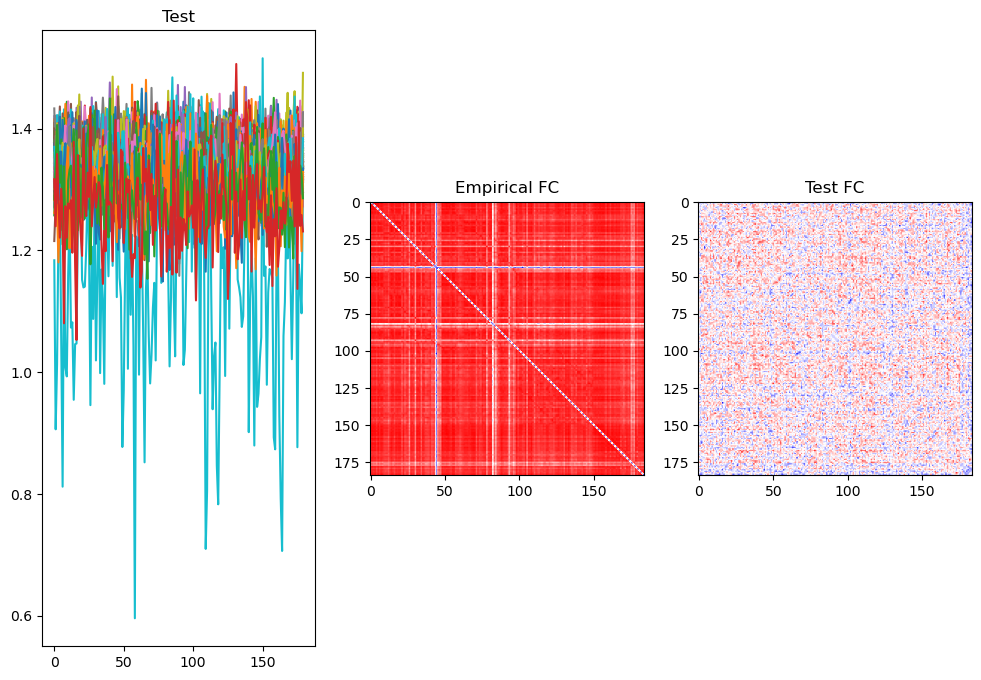

running time is  1691.5064225196838 's
dlPFC 1 4615 Schaefer100+Tian+Suit 184 20
dlPFC 1 4602 Schaefer200+Tian+Suit 284 20
(284, 284)


/tmp/ipykernel_3580073/1316895587.py:41: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


epoch:  0 394.40167
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  0 0.01910444586903886 cos_sim:  -0.15466852188348862
epoch:  1 366.44754
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  1 0.01801120092848875 cos_sim:  -0.15581617889846403
epoch:  2 338.48453
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  2 0.023417540107372566 cos_sim:  -0.15578817582867074
epoch:  3 312.88846
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  3 0.013575808031752222 cos_sim:  -0.1556975066588843
epoch:  4 288.76373
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  4 0.0427899514292302 cos_sim:  -0.15573407951323565
epoch:  5 266.01486
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  5 0.024677085426832567 cos_sim:  -0.15581268213985297
epoch:  6 245.20488
ts_sim shape:(284, 180)
ts.mean shape

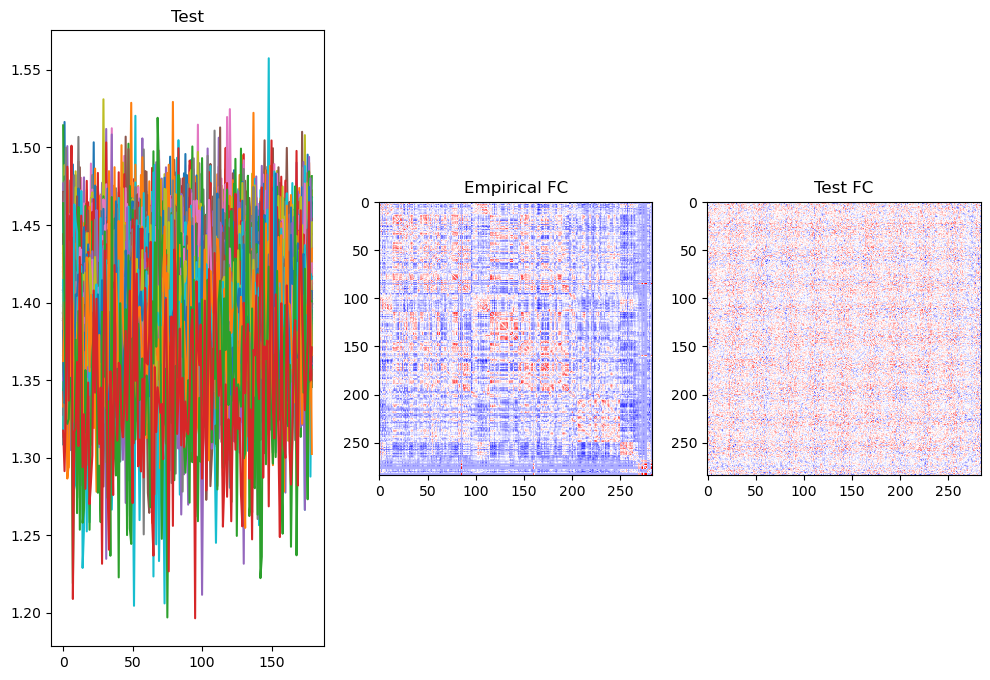

running time is  1492.3898620605469 's
dlPFC 1 4608 Schaefer200+Tian+Suit 284 20
(284, 284)


/tmp/ipykernel_3580073/1316895587.py:41: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


epoch:  0 411.77725
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  0 0.05180710535222043 cos_sim:  0.021461494949433054
epoch:  1 382.43585
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  1 0.028869281504166806 cos_sim:  0.01888579587782195
epoch:  2 355.17233
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  2 0.025973683812349723 cos_sim:  0.01931069809465336
epoch:  3 328.4523
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  3 0.004179419448971061 cos_sim:  0.019406156134899728
epoch:  4 306.13272
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  4 0.04293004997128218 cos_sim:  0.018387678696875853
epoch:  5 283.02783
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 0
ts.mean nan 0
epoch:  5 0.02341386371378125 cos_sim:  0.018715394663722004
epoch:  6 262.1627
ts_sim shape:(284, 180)
ts.mean shape:(

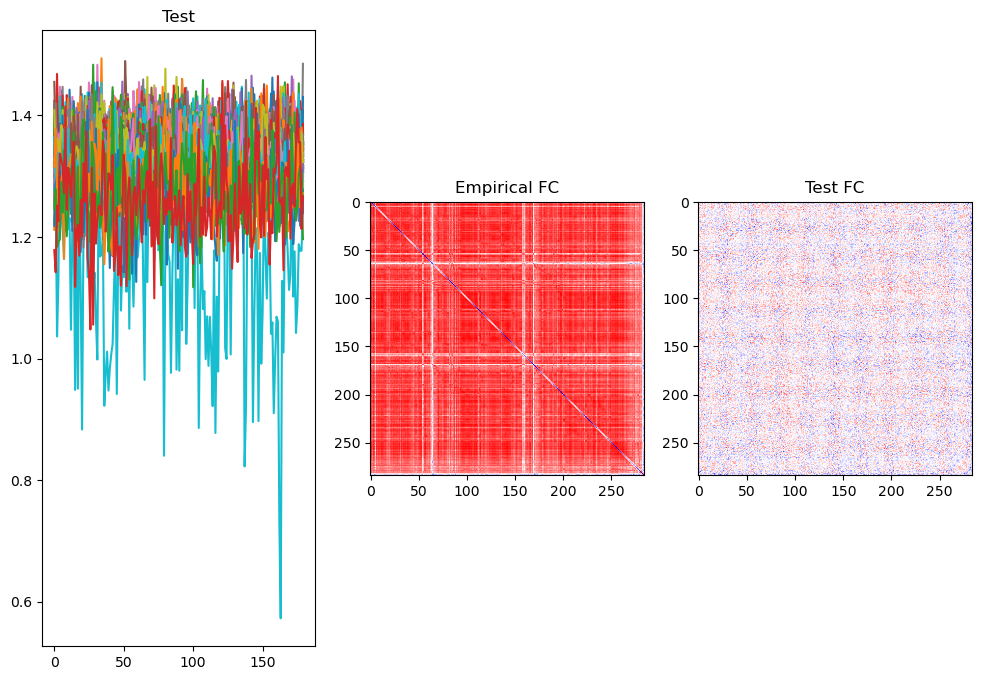

running time is  1485.2168610095978 's
dlPFC 1 4615 Schaefer200+Tian+Suit 284 20
(284, 284)


/tmp/ipykernel_3580073/1316895587.py:41: RuntimeWarning: divide by zero encountered in divide
  dist = np.nan_to_num(1/sc)


epoch:  0 nan
ts_sim shape:(284, 180)
ts.mean shape:(284, 180)
ts_sim nan 45440
ts.mean nan 0


ValueError: Input contains NaN.

In [ ]:
iterate(stim_sites = {'dlPFC': ['4602', '4607', '4615'], 'pSTS': ['A941312', 'D941352', 'B941344', 'DB941351']}, sessions = [1,2], 
        parcellations = {'Schaefer100+Tian+Suit': [184], 'Schaefer200+Tian+Suit': [284]},
        epochs = [20], csv_path = 'rww_res/rww_results.csv')

#'4602', 
#'Schaefer100+Tian+Suit': [100, 184], '

In [3]:
pd.read_pickle('ts_sim.pkl')

array([[2.1024616 , 1.206977  , 1.1801475 , ...,        nan,        nan,
               nan],
       [1.789767  , 1.0705312 , 1.191303  , ...,        nan,        nan,
               nan],
       [1.8883276 , 1.1204734 , 1.1950499 , ...,        nan,        nan,
               nan],
       ...,
       [1.1967232 , 0.90723854, 1.0921633 , ...,        nan,        nan,
               nan],
       [1.3077576 , 1.1085973 , 0.9385073 , ...,        nan,        nan,
               nan],
       [1.7207578 , 0.84772617, 0.9192505 , ...,        nan,        nan,
               nan]], dtype=float32)

In [12]:
np.shape(pd.read_pickle('bold_train.pkl')[0])

(100, 20)